In [33]:
import numpy as np

In [34]:
data = np.load('/projects/static2dynamic/Gravier/schron/notebooks/notebook_data/eb_velocity_v5.npz')

In [35]:
idx = (data['sample_labels'] == 0)

In [36]:
from sklearn.preprocessing import StandardScaler

In [37]:
import numpy as np
from collections import Counter

# Charger les labels
labels = data['sample_labels']

# Décoder si c'est en bytes (cas fréquent dans les .npz)
if labels.dtype.type is np.bytes_:
    labels = np.char.decode(labels)

# Compter les occurrences
label_counts = Counter(labels)

# Afficher proprement
for label, count in label_counts.items():
    print(f"{label}: {count}")


0: 2381
1: 4163
2: 3278
3: 3665
4: 3332


In [38]:
list(data.keys())

['pcs',
 'phate',
 'delta_embedding',
 'color',
 'ixs',
 'sample_labels',
 'pcs_delta']

In [39]:
scaler = StandardScaler()
pcs = scaler.fit_transform(data['pcs'][:, :])  


sample_labels = data['sample_labels'][:]

unique_labels = np.unique(sample_labels)
for label in unique_labels:
    mask = sample_labels == label
    pcs_label = pcs[mask]
    pcs_label = pcs_label[:, :]
    np.savez(f'pcs_label_{label}.npz', pcs=pcs_label)

In [40]:
scaler.mean_

array([ 5.21545682e+01,  2.21619448e-01,  7.44937410e-02,  5.77009669e-02,
        4.39968580e-02, -2.06239767e-02,  4.48231720e-03,  4.04870804e-03,
        5.75437393e-03,  6.13047718e-03, -3.07098860e-04, -4.88112994e-03,
        1.82359386e-03,  7.28442019e-03, -3.74926152e-03, -4.48322674e-03,
        7.11622827e-03,  9.91073057e-04, -1.67832142e-03, -5.12981265e-03,
        1.80062056e-03, -8.16939655e-03, -3.47255122e-04,  2.61791845e-03,
        1.43513791e-03, -9.12174572e-04,  3.58725260e-03,  3.46801615e-04,
        4.65844096e-04,  3.17688656e-03, -1.42029238e-03,  5.05534584e-04,
        4.07490636e-04,  2.03761816e-03, -2.71456494e-03,  2.10936744e-03,
       -1.59985264e-03,  2.59157369e-03, -1.00604989e-03, -8.66590363e-04,
       -1.35890844e-03, -1.10175997e-03, -9.60811675e-04,  1.60811164e-03,
        1.90814721e-03,  1.02241200e-04,  4.56774937e-04,  3.90076288e-03,
        1.23602406e-03, -9.53672470e-05, -9.34599424e-04,  1.97306194e-04,
        7.92828014e-04, -

In [41]:
scaler.var_

array([ 6.99925164, 39.41327745, 21.45273373, 20.23334626, 11.37334989,
        8.56286309,  8.07230915,  6.65863237,  6.07227024,  5.15356689,
        4.32347468,  4.11363734,  3.55618319,  3.21678133,  3.00851096,
        2.67420076,  2.60235801,  2.35305889,  2.2610859 ,  2.07506127,
        1.99404942,  1.97282041,  1.84077251,  1.77736094,  1.66536457,
        1.64951475,  1.55647457,  1.46022171,  1.40957204,  1.39353006,
        1.35500467,  1.33173602,  1.31372706,  1.29046881,  1.24071841,
        1.20284413,  1.16317611,  1.11067672,  1.09897207,  1.08267129,
        1.05866154,  1.01202492,  0.99705389,  0.97610087,  0.96919287,
        0.96011475,  0.93982904,  0.92765631,  0.90434103,  0.87590664,
        0.86297146,  0.85791148,  0.84799118,  0.82447679,  0.81820492,
        0.7998131 ,  0.78183323,  0.7726799 ,  0.75925508,  0.74943124,
        0.73527084,  0.72554899,  0.72074223,  0.71616953,  0.71055837,
        0.70552131,  0.70170276,  0.69504452,  0.69410508,  0.68

In [42]:
import pickle

# Sauvegarde
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)



In [43]:
# Chargement
with open('scaler.pkl', 'rb') as f:
    scaler_loaded = pickle.load(f)


In [44]:
pcs_label.var(axis=0).min()

0.3792557577346581

In [45]:
pcs_label.var(axis=0).mean()

1.3572893457588293

In [46]:
plt.figure(figsize=(8, 8))
for label, color in zip(labels_to_visualize, colors):
    mask_label = labels_interleaved == label
    plt.scatter(
        pcs_interleaved[mask_label, 0],
        pcs_interleaved[mask_label, 1],
        alpha=0.3,  # Plus transparent
        label=f'Label {label}',
        color=color
    )

plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Visualisation des classes (ordre intercalé)')
plt.legend()
plt.grid(True)
plt.show()


NameError: name 'labels_to_visualize' is not defined

<Figure size 800x800 with 0 Axes>

In [47]:
pcs.var(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [48]:
pcs.mean(axis=0)

array([-1.59493482e-15, -6.25623447e-16, -1.54405427e-15, -6.52839391e-17,
       -9.33751758e-16,  9.56472417e-16,  3.42440334e-16, -1.31234580e-16,
       -5.65319966e-16,  1.74688995e-16,  3.47156752e-16,  1.68457647e-16,
       -6.14137699e-16,  3.25554964e-16,  6.71454225e-17,  2.19270533e-16,
        1.69513807e-17,  2.21080858e-16,  4.47548136e-17,  1.56886085e-16,
        1.07913229e-16,  3.57328901e-17, -2.48646655e-16, -5.27750347e-17,
        9.24140695e-19,  3.94740097e-18, -4.60354086e-17,  9.05063790e-17,
        1.66371729e-16,  1.04150656e-16, -1.93257622e-16,  7.70221762e-17,
        6.93633601e-17, -1.60219592e-16, -4.03605246e-16, -2.12374133e-16,
        1.34475673e-16, -2.05159234e-17, -1.66972421e-16,  3.85102630e-17,
       -1.78276642e-16,  4.89926588e-17,  9.43877700e-17,  1.46449896e-16,
       -7.22628516e-17,  1.50410499e-16, -1.94993687e-17, -4.17711594e-17,
        4.27530589e-17, -1.27861466e-17,  9.53861720e-17,  4.58901865e-17,
        7.59577641e-17, -

Dataset: Embryoid body RNA-seq dim 100
Total samples: 16819
Number of time points: 5
Time 0: 2381 samples
Time 1: 4163 samples
Time 2: 3278 samples
Time 3: 3665 samples
Time 4: 3332 samples


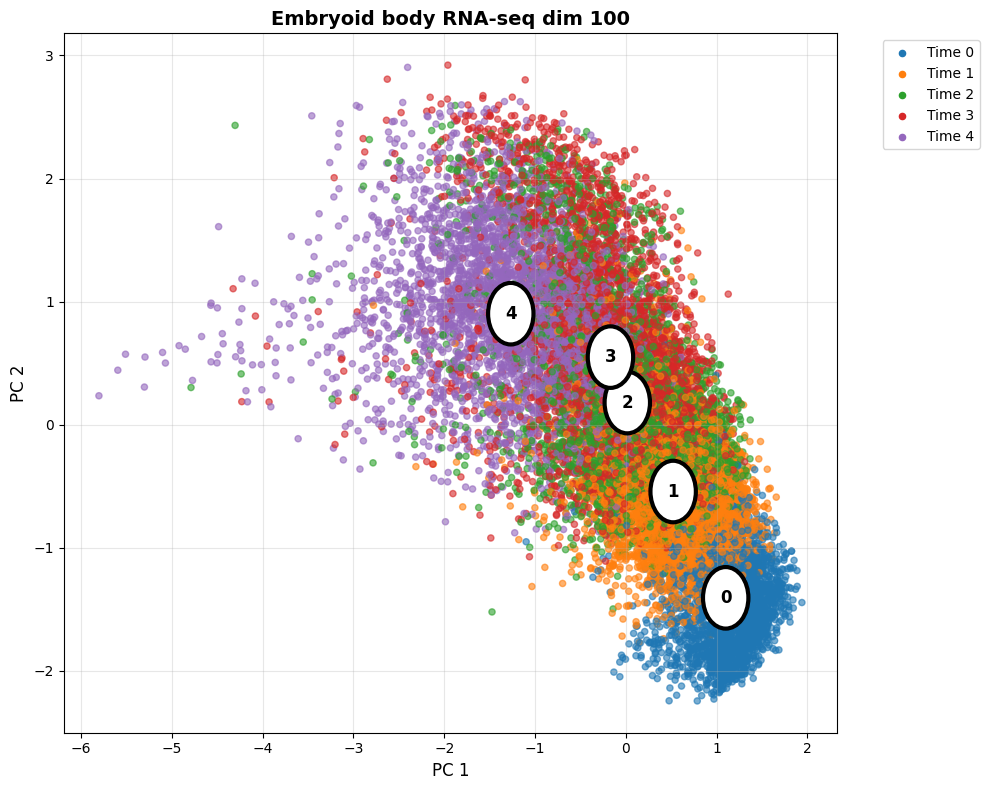

In [55]:
def visualize_pca_dataset(pcs, sample_labels, title="Embryoid body RNA-seq dim 100", 
                         figsize=(10, 8), alpha=0.6, random_state=42):
    """
    Visualise les données PCA avec échantillonnage intercalé pour rapport scientifique.
    
    Parameters:
    -----------
    pcs : array-like, shape (n_samples, n_components)
        Données PCA standardisées
    sample_labels : array-like, shape (n_samples,)
        Labels des échantillons
    title : str
        Titre du graphique
    figsize : tuple
        Taille de la figure
    alpha : float
        Transparence des points
    random_state : int
        Graine pour la reproductibilité
    """
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.patches import Circle
    
    # Obtenir les labels uniques
    unique_labels = np.unique(sample_labels)
    n_labels = len(unique_labels)
    
    # Couleurs distinctes prédéfinies
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', 
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    
    # Créer un échantillonnage intercalé
    np.random.seed(random_state)
    
    # Collecter les indices pour chaque label
    label_indices = {}
    for label in unique_labels:
        label_indices[label] = np.where(sample_labels == label)[0]
        # Mélanger les indices de chaque label
        np.random.shuffle(label_indices[label])
    
    # Déterminer le nombre maximum d'échantillons par label pour l'intercalage
    max_samples = max(len(indices) for indices in label_indices.values())
    
    # Créer l'ordre intercalé
    intercalated_indices = []
    intercalated_labels = []
    
    for i in range(max_samples):
        for label in unique_labels:
            if i < len(label_indices[label]):
                idx = label_indices[label][i]
                intercalated_indices.append(idx)
                intercalated_labels.append(label)
    
    # Convertir en arrays numpy
    intercalated_indices = np.array(intercalated_indices)
    intercalated_labels = np.array(intercalated_labels)
    
    # Extraire les données PCA intercalées
    pcs_intercalated = pcs[intercalated_indices]
    
    # Créer la visualisation
    fig, ax = plt.subplots(figsize=figsize)
    
    # Mélanger complètement tous les points pour éviter que les labels se masquent
    final_shuffle_indices = np.arange(len(intercalated_indices))
    np.random.shuffle(final_shuffle_indices)
    
    pcs_final = pcs_intercalated[final_shuffle_indices]
    labels_final = intercalated_labels[final_shuffle_indices]
    
    # Créer un mapping couleur pour chaque label
    color_map = {}
    for i, label in enumerate(unique_labels):
        color_map[label] = colors[i % len(colors)]
    
    # Approche vectorisée plus efficace
    # Créer un array de couleurs pour tous les points
    point_colors = [color_map[label] for label in labels_final]
    
    # Tracer tous les points d'un coup avec leurs couleurs respectives
    ax.scatter(pcs_final[:, 0], pcs_final[:, 1], 
                c=point_colors, alpha=alpha, s=20)
    
    # Ajouter la légende manuellement
    for label in unique_labels:
        ax.scatter([], [], color=color_map[label], label=f'Time {label}', s=20)
    
    # Ajouter les numéros entourés au centroïde de chaque distribution
    for label in unique_labels:
        mask = sample_labels == label
        pcs_label = pcs[mask]
        
        if len(pcs_label) > 0:
            # Calculer le centroïde pour ce label
            centroid_x = np.mean(pcs_label[:, 0])
            centroid_y = np.mean(pcs_label[:, 1])
            
            # Ajouter le cercle blanc avec bordure noire
            circle = Circle((centroid_x, centroid_y), radius=0.25, 
                          facecolor='white', edgecolor='black', linewidth=3, zorder=10)
            ax.add_patch(circle)
            
            # Ajouter le numéro en noir épais
            ax.text(centroid_x, centroid_y, str(label), 
                   fontsize=12, fontweight='bold', color='black',
                   ha='center', va='center', zorder=11)
    
    ax.set_xlabel('PC 1', fontsize=12)
    ax.set_ylabel('PC 2', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    # Afficher quelques statistiques
    print(f"Dataset: {title}")
    print(f"Total samples: {len(pcs)}")
    print(f"Number of time points: {n_labels}")
    for label in unique_labels:
        count = np.sum(sample_labels == label)
        print(f"Time {label}: {count} samples")
    
    plt.show()

# Utiliser la fonction avec nos données
visualize_pca_dataset(pcs, sample_labels)